<a href="https://colab.research.google.com/github/THE5NEON/Python-Labs/blob/main/%D0%9B%D0%A07_%D0%A2%D0%BE%D1%87%D0%B5%D0%BD%D1%8E%D0%BA_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

**Виконав:** Точенюк Ярослав, група 4-9.

Під час CV використано Pipeline зі стандартизацією всередині кожного фолду; це усуває витік між фолдами.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
import io, base64, zlib
from pathlib import Path

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

Для відтворюваності використано вбудовану точну копію CSV викладача (стиснену без втрат).

In [2]:
encoded = '...'
df = pd.read_csv(io.BytesIO(zlib.decompress(base64.b64decode(encoded))))
display(df.head())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [3]:
# Альтернативний спосіб (не потрібний, якщо дані вже завантажені):
# import kagglehub, os
# path = kagglehub.dataset_download("unmoved/cure-the-princess")
# df = pd.read_csv(os.path.join(path, "data.csv"))

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
display(df.head())
print("Розмір:", df.shape)
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір: (2338, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [5]:
display(df.isna().sum().rename("Пропуски"))
missing = int(df.isna().sum().sum())
duplicates = int(df.duplicated().sum())
print("Пропуски:", missing, "Дублікати:", duplicates)

,Пропуски
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Пропуски: 0 Дублікати: 0


In [6]:
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


**Висновок за первинним оглядом:**  
Результат наведено нижче.

In [7]:
display(Markdown(f"**Висновок:** {df.shape[0]} рядків, {df.shape[1]-1} числових ознак, {missing} пропусків і {duplicates} дублікатів. Цільова змінна бінарна; числові ознаки мають різні масштаби."))

**Висновок:** 2338 рядків, 13 числових ознак, 0 пропусків і 0 дублікатів. Цільова змінна бінарна; числові ознаки мають різні масштаби.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
X = df.drop(columns="Cured")
y = df["Cured"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Навчальна:", X_train.shape, "Тестова:", X_test.shape)
assert not set(X_train.index) & set(X_test.index)

Навчальна: (1870, 13) Тестова: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [9]:
counts = y_train.value_counts().sort_index()
display(pd.DataFrame({"Кількість": counts, "Частка, %": counts / len(y_train) * 100}))

,Кількість,"Частка, %"
Cured,,
0,946,50.588235
1,924,49.411765


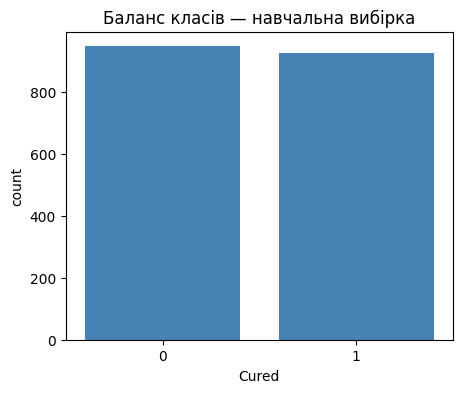

In [10]:
plt.figure(figsize=(5,4))
sns.countplot(x=y_train, color="steelblue", saturation=1)
plt.title("Баланс класів — навчальна вибірка")
plt.show()

**Висновок:**  
Результат наведено нижче.

In [11]:
display(Markdown(f"**Висновок:** клас 0 — {counts[0]}, клас 1 — {counts[1]}. Частка меншого класу {counts.min()/len(y_train):.1%}; класи близькі до збалансованих. При дисбалансі Accuracy може приховувати помилки меншого класу."))

**Висновок:** клас 0 — 946, клас 1 — 924. Частка меншого класу 49.4%; класи близькі до збалансованих. При дисбалансі Accuracy може приховувати помилки меншого класу.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

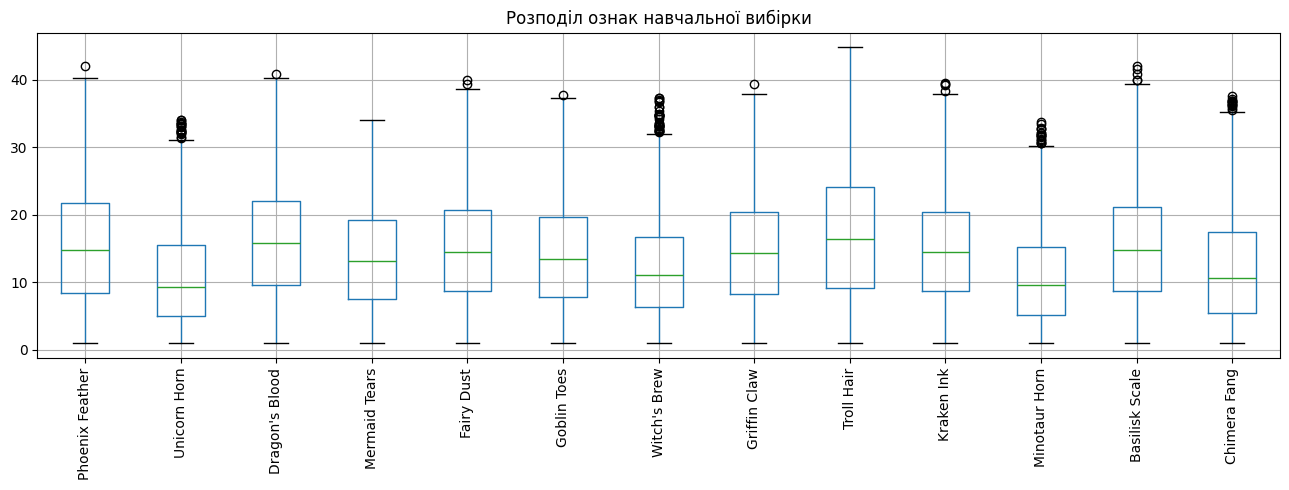

In [12]:
X_train.boxplot(figsize=(13,5), rot=90)
plt.title("Розподіл ознак навчальної вибірки")
plt.tight_layout()
plt.show()

In [13]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
outliers = ((X_train < q1 - 1.5*iqr) | (X_train > q3 + 1.5*iqr)).sum().sort_values(ascending=False)
display(outliers.rename("Потенційні викиди"))

,Потенційні викиди
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
Результат наведено нижче.

In [14]:
display(Markdown(f"**Висновок:** найбільше потенційних викидів має {outliers.index[0]} ({outliers.iloc[0]}). Не видаляємо їх автоматично, бо вони можуть бути реальними спостереженнями."))

**Висновок:** найбільше потенційних викидів має Witch's Brew (33). Не видаляємо їх автоматично, бо вони можуть бути реальними спостереженнями.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

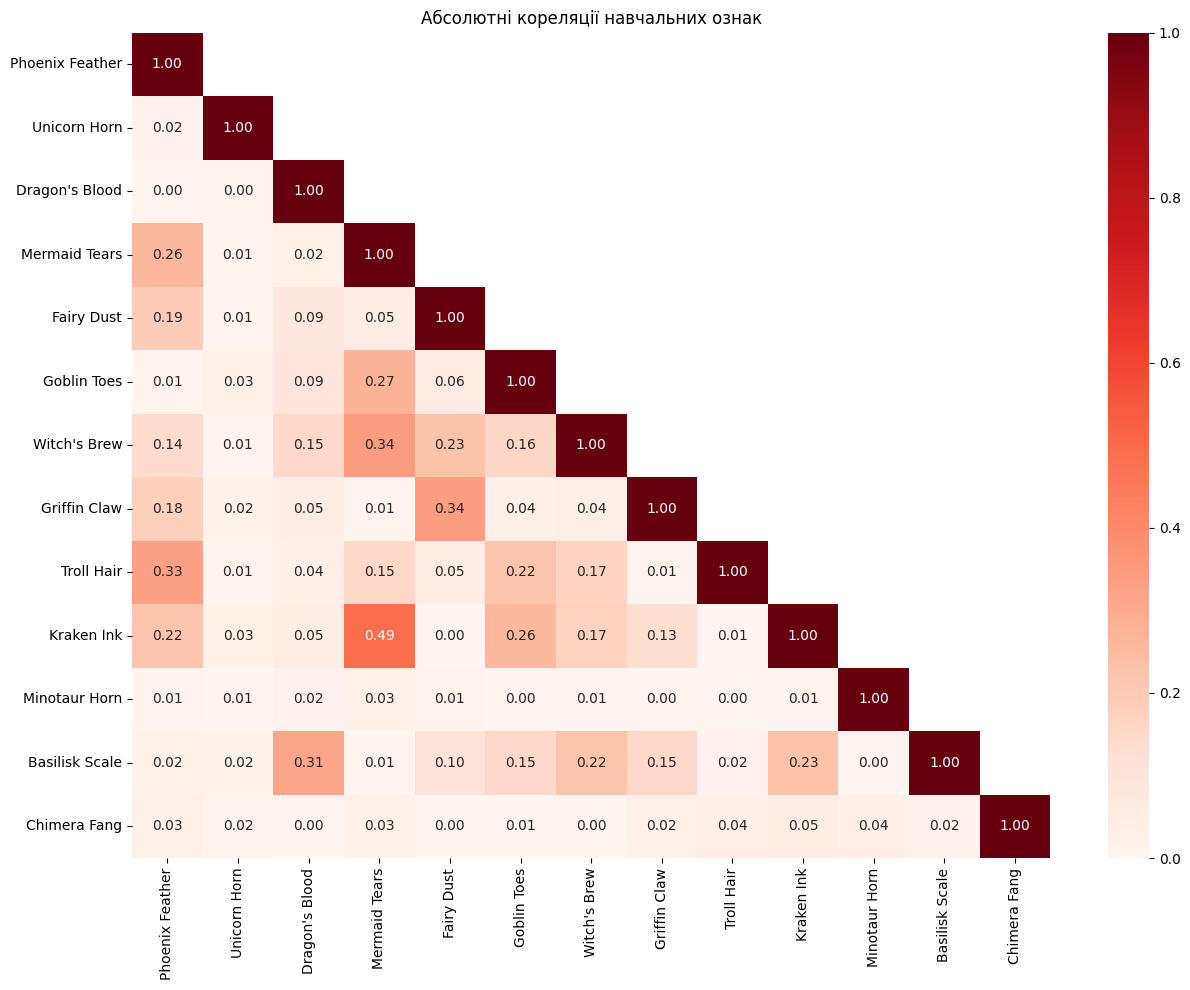

Mermaid Tears  Kraken Ink      0.490744
               Witch's Brew    0.343493
Fairy Dust     Griffin Claw    0.339391
dtype: float64

In [15]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)
plt.figure(figsize=(13,10))
sns.heatmap(mtx, mask=mask, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
plt.title("Абсолютні кореляції навчальних ознак")
plt.tight_layout()
plt.show()
pairs = mtx.where(np.triu(np.ones_like(mtx,dtype=bool),k=1)).stack().sort_values(ascending=False)
display(pairs.head(3))

In [16]:
target_corr = pd.concat([X_train,y_train],axis=1).corr()["Cured"].drop("Cured")
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
display(target_corr)

,Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


**Висновок про кореляції:**  
Результат наведено нижче.

In [17]:
display(Markdown(f"**Висновок:** найбільша абсолютна кореляція між {pairs.index[0][0]} та {pairs.index[0][1]} ({pairs.iloc[0]:.3f}). Найсильніший зв’язок із Cured: {target_corr.index[0]} ({target_corr.iloc[0]:.3f}). Кореляція не означає причинності."))

**Висновок:** найбільша абсолютна кореляція між Mermaid Tears та Kraken Ink (0.491). Найсильніший зв’язок із Cured: Troll Hair (0.489). Кореляція не означає причинності.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert np.allclose(X_train_scaled.mean(axis=0),0,atol=1e-10)
print("Стандартизацію виконано лише за параметрами навчальних даних.")

Стандартизацію виконано лише за параметрами навчальних даних.


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [19]:
model = LogisticRegression()
model.fit(X_train_scaled,y_train)
y_pred = model.predict(X_test_scaled)
base_acc = accuracy_score(y_test,y_pred)
base_f1 = f1_score(y_test,y_pred)
print(f"Accuracy: {base_acc:.4f}; F1: {base_f1:.4f}")
print(classification_report(y_test,y_pred,zero_division=0))

Accuracy: 0.8932; F1: 0.8941
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

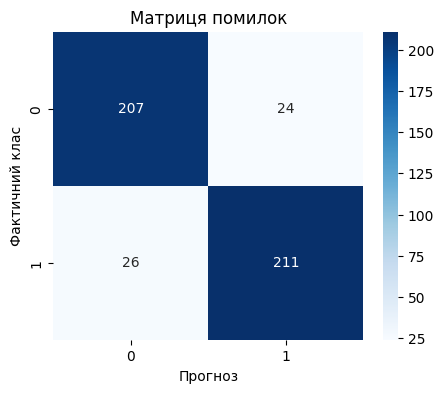

In [20]:
conf = confusion_matrix(y_test,y_pred,labels=[0,1])
plt.figure(figsize=(5,4))
sns.heatmap(conf,annot=True,fmt="d",cmap="Blues",xticklabels=[0,1],yticklabels=[0,1])
plt.xlabel("Прогноз")
plt.ylabel("Фактичний клас")
plt.title("Матриця помилок")
plt.show()

In [21]:
examples = pd.DataFrame({"Фактичний клас":y_test.to_numpy(),"Прогноз":y_pred},index=y_test.index)
display(examples.sample(10,random_state=42))

,Фактичний клас,Прогноз
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
Результат наведено нижче.

In [22]:
display(Markdown(f"**Висновок:** FP = {conf[0,1]}, FN = {conf[1,0]}. Більше помилок: {'FP' if conf[0,1]>conf[1,0] else 'FN' if conf[1,0]>conf[0,1] else 'порівну'}. Accuracy недостатньо для опису типів помилок; потрібні також precision, recall і F1."))

**Висновок:** FP = 24, FN = 26. Більше помилок: FN. Accuracy недостатньо для опису типів помилок; потрібні також precision, recall і F1.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [23]:
pipe = Pipeline([("scaler",StandardScaler()),("model",LogisticRegression())])
param_grid = {"model__C":[0.01,0.1,1,10,100],"model__solver":["lbfgs","liblinear"],"model__max_iter":[200,500]}
param_dist = {"model__C":np.logspace(-3,3,40),"model__solver":["lbfgs","liblinear"],"model__max_iter":[200,500,1000]}
cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=42)

In [24]:
grid = GridSearchCV(pipe,param_grid,cv=cv,scoring="accuracy",n_jobs=1)
grid.fit(X_train,y_train)
print(grid.best_params_, "CV Accuracy:",grid.best_score_)

{'model__C': 10, 'model__max_iter': 200, 'model__solver': 'lbfgs'} CV Accuracy: 0.867379889149552


In [25]:
random_search = RandomizedSearchCV(pipe,param_dist,n_iter=20,cv=cv,scoring="accuracy",random_state=42,n_jobs=1)
random_search.fit(X_train,y_train)
print(random_search.best_params_, "CV Accuracy:",random_search.best_score_)

{'model__solver': 'liblinear', 'model__max_iter': 1000, 'model__C': np.float64(3.4551072945922217)} CV Accuracy: 0.8673798891495522


In [26]:
best_search = max([grid,random_search],key=lambda s:s.best_score_)
best_model = best_search.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_acc = accuracy_score(y_test,tuned_pred)
print(type(best_search).__name__,f"Accuracy: {tuned_acc:.4f}")
print(classification_report(y_test,tuned_pred,zero_division=0))

RandomizedSearchCV Accuracy: 0.8932
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Результат наведено нижче.

In [27]:
display(Markdown(f"**Висновок:** GridSearchCV: {grid.best_params_}; RandomizedSearchCV: {random_search.best_params_}. За CV обрано {type(best_search).__name__}. Тестова Accuracy базової моделі {base_acc:.4f}, налаштованої {tuned_acc:.4f}; зміна {tuned_acc-base_acc:+.4f}."))

**Висновок:** GridSearchCV: {'model__C': 10, 'model__max_iter': 200, 'model__solver': 'lbfgs'}; RandomizedSearchCV: {'model__solver': 'liblinear', 'model__max_iter': 1000, 'model__C': np.float64(3.4551072945922217)}. За CV обрано RandomizedSearchCV. Тестова Accuracy базової моделі 0.8932, налаштованої 0.8932; зміна +0.0000.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [28]:
models = {"Logistic Regression":best_model,"SVC":Pipeline([("scaler",StandardScaler()),("model",SVC())]),"Decision Tree":DecisionTreeClassifier(random_state=42)}
results = []
for name, estimator in models.items():
    estimator.fit(X_train,y_train)
    pred = estimator.predict(X_test)
    results.append({"Модель":name,"Accuracy":accuracy_score(y_test,pred),"F1-score":f1_score(y_test,pred)})
comparison = pd.DataFrame(results).sort_values(["Accuracy","F1-score"],ascending=False).reset_index(drop=True)
display(comparison)
print("Найкраща модель:",comparison.iloc[0]["Модель"])
assert comparison[["Accuracy","F1-score"]].apply(lambda s:s.between(0,1).all()).all()
assert conf.sum()==len(y_test)

,Модель,Accuracy,F1-score
0,SVC,0.959402,0.960000
1,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.863248,0.863248


Найкраща модель: SVC


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

In [29]:
display(Markdown(f"""### Підсумкові висновки
1. Датасет має {len(df)} рядків та {X.shape[1]} ознак; пропусків {missing}, дублікатів {duplicates}.
2. Найбільше потенційних викидів у {outliers.index[0]} ({outliers.iloc[0]}); найсильніший зв’язок із Cured має {target_corr.index[0]} ({target_corr.iloc[0]:.3f}). Аналіз виконано лише на навчальних даних.
3. Базова логістична регресія: Accuracy {base_acc:.4f}, F1 {base_f1:.4f}.
4. Після підбору Accuracy = {tuned_acc:.4f}, зміна {tuned_acc-base_acc:+.4f}; параметри обрано за CV, а не за тестом.
5. На однаковій тестовій вибірці найкраща модель за Accuracy (при рівності — F1): **{comparison.iloc[0]["Модель"]}**, Accuracy {comparison.iloc[0]["Accuracy"]:.4f}, F1 {comparison.iloc[0]["F1-score"]:.4f}. Для остаточного підтвердження узагальнення потрібні незалежні дані."""))

### Підсумкові висновки
1. Датасет має 2338 рядків та 13 ознак; пропусків 0, дублікатів 0.
2. Найбільше потенційних викидів у Witch's Brew (33); найсильніший зв’язок із Cured має Troll Hair (0.489). Аналіз виконано лише на навчальних даних.
3. Базова логістична регресія: Accuracy 0.8932, F1 0.8941.
4. Після підбору Accuracy = 0.8932, зміна +0.0000; параметри обрано за CV, а не за тестом.
5. На однаковій тестовій вибірці найкраща модель за Accuracy (при рівності — F1): **SVC**, Accuracy 0.9594, F1 0.9600. Для остаточного підтвердження узагальнення потрібні незалежні дані.